# LELA60331 Week 4 Seminar: Regression and gradient descent — SOLUTIONS

This week we will look at regression and at model training using gradient descent.

We will start by looking at fitting linear regression models.

This sheet uses only **plain Python**: lists, loops, functions and list comprehensions, plus the `math`, `random` and `statistics` modules that come with every Python installation. These are all covered in the **Week 4 Python workbook (LELA60341)**, especially writing your own functions with `def` and building lists with list comprehensions. We use `matplotlib` only to draw graphs.

### Linear regression with one predictor

In this (made up) data set y is the exam results of a group of students and x is the number of hours spent studying.

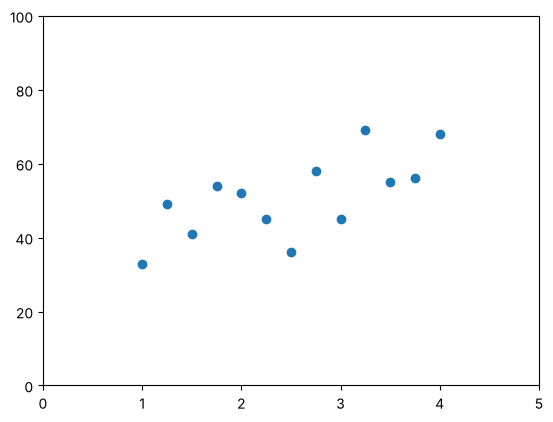

In [ ]:
import math
import random
import statistics
import matplotlib.pyplot as plt

x = [1.00, 1.25, 1.50, 1.75, 2.00, 2.25, 2.50, 2.75, 3.00, 3.25, 3.50, 3.75, 4.00]
y = [33, 49, 41, 54, 52, 45, 36, 58, 45, 69, 55, 56, 68]

plt.scatter(x, y)
plt.xlim(0, 5)
plt.ylim(0, 100)
plt.show()

In linear regression we fit a line to the data that allows us to predict y from x. The equation for this is as follows (note that I am using the machine-learning term bias in place of the term intercept which is more commonly used in statistics).

y = bias + x*weight [+ error]

Let's start by setting a random weight and setting our bias to zero. `random.random()` gives a random number between 0 and 1.

Note: Computers cannot actually generate random numbers, just numbers that appear random. So we would do better to consider the numbers generated to be pseudo-random. The algorithm deployed uses a "seed" during generation. If the seed is held constant then we will get the same "random" value each time. I set the seed here with `random.seed(1)` just so that everyone gets the same line and things don't get confusing. If I hadn't set this I would expect a different weight everytime I ran the code.

In [ ]:
random.seed(1)
weight = random.random()
bias = 0
weight

0.13436424411240122

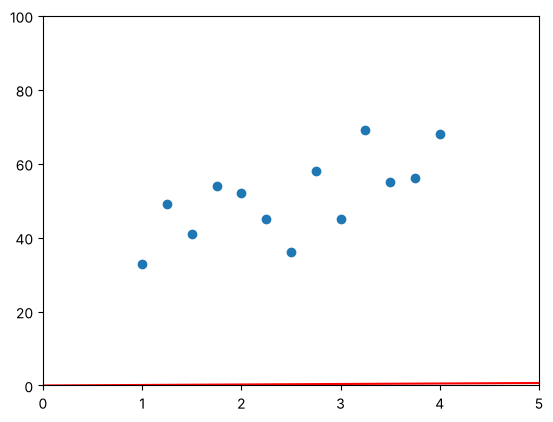

In [ ]:
# We will draw the data with a fitted line several times, so we write a function for it
def plot_fit(bias, weight):
    plt.scatter(x, y)
    plt.xlim(0, 5)
    plt.ylim(0, 100)
    line_x = [0, 5]
    line_y = [bias, bias + 5 * weight]      # the line's height at x = 0 and at x = 5
    plt.plot(line_x, line_y, color='red')
    plt.show()

plot_fit(bias, weight)

As you can see this line isn't a very good fit to the data. If we used it for predictions we would get very bad estimates.

We will use gradient descent to find the line of best fit. Note: it is called simply gradient descent when we update weights based on the whole data set as we will here. If we update weights based on random subsets of the data (mini-batch training) it is called stochastic gradient descent. These variants will be explained in a forthcoming lecture.

Gradient descent works as follows: \
Initialise weights to e.g. random values \
For a given number of N iterations:
1. Predict each y value given x, bias and the current weight(s), giving us y_hat
2. Calculate the loss (for reporting/monitoring). For linear regression this is the "mean squared error". We calculate a vector of item-specific "errors" by subtracting the vector of real y values from the vector of estimated y_hat values. We then calculate the dot product of this vector with itself (the sum of the squared values) and divide that by the number of data points.
3. Calculate dw - the gradient of the loss function with regard to each weight. For linear regression this is the dot product of the vector of x values for the given feature and the vector of errors, divided by the number of data points in our data.
4. Calculate db - the gradient of the loss function with regard to the bias. For linear regression this is the sum of the vector of errors, divided by the number of data points in our data.
5. Update each weight (in this first example there is only one) by setting it to be the current weight minus dw times the learning rate
6. Update the bias by setting it to be the current bias minus db times the learning rate
7. Repeat until done

In plain Python a **vector** is just a list of numbers. We need the **dot product** of two vectors several times, so here is a function for it. It multiplies the two lists element by element and adds up the results (just like the ⭐ challenge in Exercise 4 of the Week 3 Python workbook).

In [ ]:
def dot(a, b):
    # the dot product of two lists of the same length
    total = 0
    for i in range(len(a)):
        total += a[i] * b[i]
    return total

print(dot([1, 2, 3], [4, 5, 6]))     # 1*4 + 2*5 + 3*6 = 32

32


**Activity 1**

Complete the code below so that it finds the line of best fit. Each blank is one step of the gradient descent recipe above.

The predictions and the errors need one value for every data point, so they are **lists**, which you can build with a list comprehension. For example, `[bias + xi * weight for xi in x]` gives a prediction for every `x`. The other blanks are single numbers: use `dot()` and `sum()`.

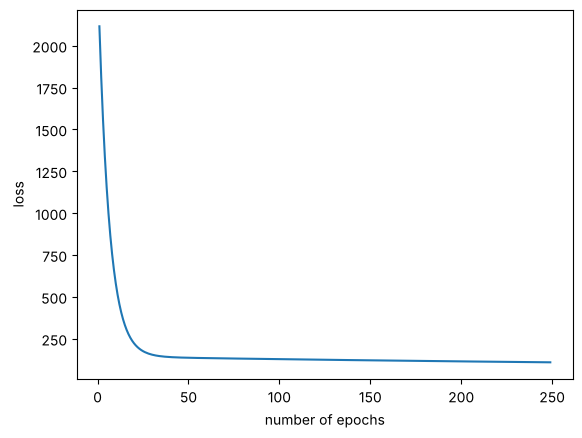

In [ ]:
n_iters = 250
weight = random.random()
bias = 0
linear_loss = []

num_samples = len(y)
lr = 0.01

for i in range(n_iters):
    y_est = [bias + xi * weight for xi in x]                    # 1. a list: a prediction for every x
    errors = [y_est[k] - y[k] for k in range(num_samples)]      # 2. a list: each prediction minus the real y value
    loss = dot(errors, errors) / num_samples                    #    the mean squared error
    linear_loss.append(loss)

    dw = dot(x, errors) / num_samples                           # 3. gradient for the weight
    db = sum(errors) / num_samples                              # 4. gradient for the bias
    weight = weight - lr * dw                                   # 5. step the weight against its gradient
    bias = bias - lr * db                                       # 6. step the bias against its gradient

plt.plot(range(1, n_iters), linear_loss[1:])
plt.xlabel("number of epochs")
plt.ylabel("loss")
plt.show()

If we have done this correctly then when we use the bias and the weight to plot a line it should fit the data well

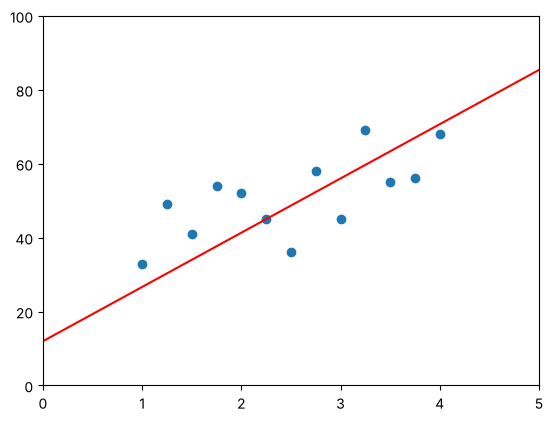

In [ ]:
plot_fit(bias, weight)

**Activity 2**

Increase the learning rate to 2 and rerun your code. What do you notice? Why does this happen?

(You may see the loss become `inf`, Python's way of writing a number too big to store, or `nan`, "not a number", which is what you get from a sum like `inf - inf`.)

In [ ]:
# Solution: rerun the Activity 1 loop with lr = 2
def train_one_predictor(lr, n_iters=250):
    weight = random.random()
    bias = 0
    losses = []
    num_samples = len(y)
    for i in range(n_iters):
        y_est = [bias + xi * weight for xi in x]
        errors = [y_est[k] - y[k] for k in range(num_samples)]
        losses.append(dot(errors, errors) / num_samples)
        dw = dot(x, errors) / num_samples
        db = sum(errors) / num_samples
        weight = weight - lr * dw
        bias = bias - lr * db
    return bias, weight, losses

b2, w2, loss2 = train_one_predictor(2)
print("first 6 losses:", loss2[:6])
print("final loss:", loss2[-1], " bias:", b2, " weight:", w2)

first 6 losses: [2495.7697469855566, 531418.0853920701, 120049562.79792994, 27125354887.028545, 6129013868553.654, 1384859710279822.2]
final loss: inf  bias: -1.0268108444027973e+295  weight: -2.8815767102601325e+295


**Solution to Activity 2**

With a learning rate of 2 the loss does not go down: it gets larger at every iteration, growing by a factor of more than 200 each time (about 2,500, then 530,000, then 120 million...) until it overflows to `inf`. The bias and weight shoot off to enormous numbers (around −10^295), and with a few more iterations they would become `inf` and then `nan`. There is no usable line.

This happens because the steps are far too big. The gradient tells us which direction to move in, but each update moves `lr * gradient`, and with `lr = 2` we jump right over the minimum to a point on the other side of the loss "valley" that is *higher* than where we started. There the gradient is bigger still, so the next jump is bigger again, and so on: the parameters oscillate with ever-increasing size and the training **diverges** instead of converging.

**Activity 3**

Decrease the learning rate to 0.001 and rerun your code. What do you notice? Why does this happen?

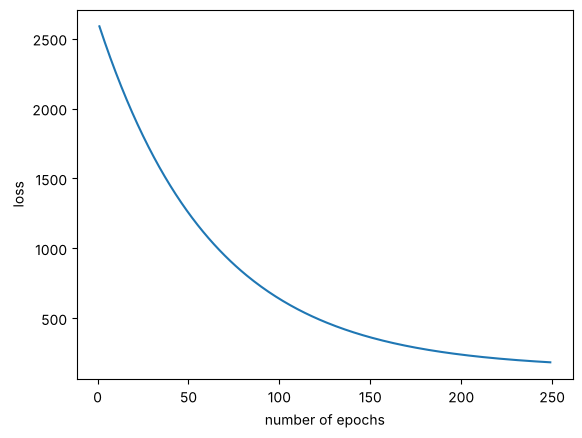

final loss: 184.1  bias: 5.82  weight: 14.37


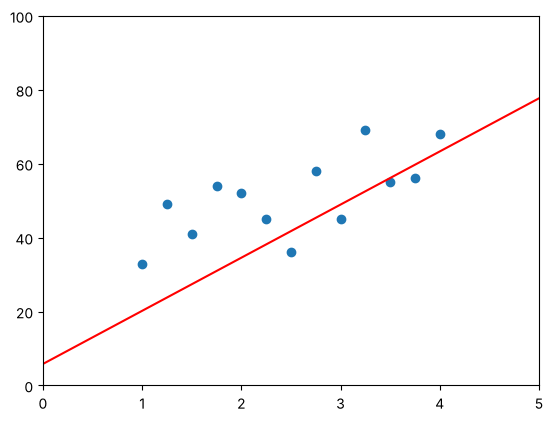

In [ ]:
# Solution: rerun the Activity 1 loop with lr = 0.001
b3, w3, loss3 = train_one_predictor(0.001)
plt.plot(range(1, 250), loss3[1:])
plt.xlabel("number of epochs")
plt.ylabel("loss")
plt.show()
print("final loss:", round(loss3[-1], 1), " bias:", round(b3, 2), " weight:", round(w3, 2))
plot_fit(b3, w3)

**Solution to Activity 3**

With a learning rate of 0.001 the loss does go down smoothly, but much more slowly. After 250 epochs it is still falling and ends at about 184, compared with about 109 for `lr = 0.01` (and about 60 for the true best-fit line). The fitted line does not match the data as well: the bias has only crept up to about 6 from its starting value of 0, so the line starts too low and is too steep.

This happens because each update is ten times smaller than before, so in the same number of iterations the parameters only travel a fraction of the way to the minimum. The model hasn't **converged** yet. We would need many more iterations (roughly ten times as many or more) to reach the same solution. Together with Activity 2 this shows the trade-off in choosing a learning rate: too large and training diverges, too small and it is very slow.

**Activity 4**

What is the predicted exam score for a student who studied for a) 1 hour and b) 4 hours?

Complete the function `predict(hours)`, which uses the fitted `bias` and `weight`. The loop at the end then uses it to predict the score for several numbers of hours.

In [ ]:
print("bias =", round(bias, 2), " weight =", round(weight, 2))

def predict(hours):
    return bias + hours * weight

print(predict(1), predict(4))
for hours in [1, 2, 3, 4]:
    print(hours, "hours:", round(predict(hours), 1))

bias = 11.98  weight = 14.68
26.653960270303703 70.69054771639271
1 hours: 26.7
2 hours: 41.3
3 hours: 56.0
4 hours: 70.7


**Solution to Activity 4**

The prediction is just the equation of the line: `bias + hours * weight`. With the fitted model (bias ≈ 11.98, weight ≈ 14.68):

* a) 1 hour: 11.98 + 1 × 14.68 ≈ **26.7**
* b) 4 hours: 11.98 + 4 × 14.68 ≈ **70.7**

A point worth discussing: after only 250 epochs with `lr = 0.01`, gradient descent has **not fully converged**. The weight comes down quickly but the bias moves only slowly, because the x values are all between 1 and 4 and not centred on zero. The exact least-squares line has bias ≈ 31.9 and weight ≈ 7.58, which would predict about 39.5 for 1 hour and 62.2 for 4 hours. Increasing `n_iters` (to, say, 20,000) brings the gradient-descent answer to these values. This is also one reason we scale the predictors in the next section.

### Linear Regression with 2 predictors

Now imagine that we acquire an additional piece of information - each student's score on a recent mock exam. We now have two features to use to make our prediction. We store them as a **list of two lists**: `x[0]` holds every student's mock exam score and `x[1]` every student's hours of study. We can plot the relationship between the variables using a bubble plot.

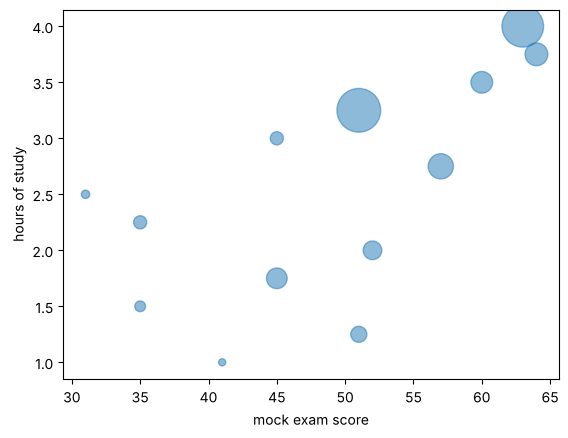

In [ ]:
x = [[41, 51, 35, 45, 52, 35, 31, 57, 45, 51, 60, 64, 63],
     [1.00, 1.25, 1.50, 1.75, 2.00, 2.25, 2.50, 2.75, 3.00, 3.25, 3.50, 3.75, 4.00]]
y = [33, 49, 41, 54, 52, 45, 36, 58, 45, 69, 55, 56, 68]

sizes = [math.exp(score / 10) for score in y]      # a bigger bubble for a higher exam result
plt.scatter(x[0], x[1], s=sizes, alpha=0.5)
plt.xlabel("mock exam score")
plt.ylabel("hours of study")
plt.show()

Before attempting to do anything with the data we will scale the predictors so that they have a mean of zero and a standard deviation of 1. This will aid learning as weights will be on manageable scales.

`statistics.mean` gives the mean of a list and `statistics.pstdev` its (population) standard deviation.

In [ ]:
for f in range(len(x)):                          # f = 0, then f = 1: one pass per feature
    mean = statistics.mean(x[f])
    sd = statistics.pstdev(x[f])
    x[f] = [(value - mean) / sd for value in x[f]]

print(x[0])

[-0.7111238197115851, 0.24192872216992092, -1.2829553448404887, -0.3299028029589827, 0.3372339763580715, -1.2829553448404887, -1.6641763615930911, 0.8137602472988246, -0.3299028029589827, 0.24192872216992092, 1.0996760098632763, 1.4808970266158787, 1.3855917724277282]


**Activity 5**

Complete the code below so that it finds the line of best fit. The critical difference is that we now have 2 features and therefore 2 weights to factor into our predictions and to update at each iteration. `x[0]` holds the values of the first feature and `x[1]` the values of the second, so `x[0][k]` is the first feature of student `k`.

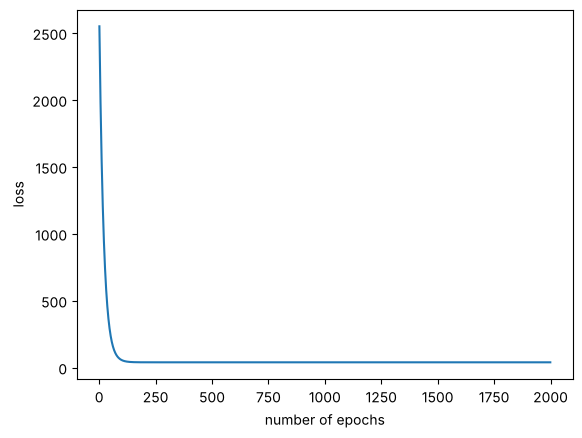

bias = 50.85  weights = [5.93, 3.34]


In [ ]:
n_iters = 2000
num_features = 2
weights = [random.random() for j in range(num_features)]
bias = 0
num_samples = len(y)
linear_loss = []
lr = 0.025
for i in range(n_iters):
    y_est = [bias + x[0][k] * weights[0] + x[1][k] * weights[1] for k in range(num_samples)]
    errors = [y_est[k] - y[k] for k in range(num_samples)]
    loss = dot(errors, errors) / num_samples
    linear_loss.append(loss)

    dw1 = dot(x[0], errors) / num_samples
    dw2 = dot(x[1], errors) / num_samples
    db = sum(errors) / num_samples
    weights[0] = weights[0] - lr * dw1
    weights[1] = weights[1] - lr * dw2
    bias = bias - lr * db

plt.plot(range(1, n_iters), linear_loss[1:])
plt.xlabel("number of epochs")
plt.ylabel("loss")
plt.show()

print("bias =", round(bias, 2), " weights =", [round(w, 2) for w in weights])